# 02 Trend groups

The logic lives in `pipeline/tract/groups.py`.

- Six features: yearly growth of jobs, people and real rent, before and after (see notebook 01)
- Clip each to its 1st and 99th percentile, then standardize
- k from 2 to 10: elbow, silhouette, Davies-Bouldin, gap statistic, stability across seeds and subsamples
- K-means vs a Gaussian mixture vs Ward clustering
- Rule for k: stable (subsample adjusted Rand at least 0.8), no group under 2% of tracts, then the best silhouette

**Output**: `trend_group` column in `trends_tract.csv`, `processed/5500/groups_*`

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 3)
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 60   # keeps the notebook small. Saved figures use 120 dpi

from pipeline.tract import groups, plots

In [2]:
r = groups.run()
print('chosen k =', r['k'], 'method =', r['method'])

chosen k = 7 method = kmeans


## Scaling check

- Raw jobs rates have a standard deviation of 4.8 points a year, population before 2019 only 1.7. The two jobs rates hold 53% of the raw variance. Without scaling, jobs would decide the groups
- After StandardScaler every feature has the same spread

In [3]:
r['scaling'].round(3)

,raw_std_pct,raw_iqr_pct,skew,scaled_std,share_of_raw_variance
jobs_growth_before,4.822,4.765,0.054,1.0,0.268
jobs_growth_after,4.809,4.714,0.671,1.0,0.266
pop_growth_before,1.687,1.803,0.275,1.0,0.033
pop_growth_after,3.727,2.702,1.641,1.0,0.160
rent_growth_before,3.083,3.320,0.270,1.0,0.110
rent_growth_after,3.766,4.319,0.228,1.0,0.163


## k from 2 to 10

In [4]:
r['metrics'].round(3)

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,gap,gap_s,gmm_bic,smallest_group_share,gap_rule_ok,ari_seeds,ari_bootstrap
0,2,16516.361,0.131,2.330,471.130,1.159,0.008,51227.807,0.467,True,0.881,0.845
1,3,15109.976,0.117,2.139,404.476,1.146,0.008,50956.670,0.305,True,0.388,0.498
2,4,13794.113,0.134,1.806,395.722,1.153,0.008,50811.796,0.032,False,0.418,0.634
3,5,12728.134,0.133,1.717,387.669,1.172,0.008,51018.927,0.031,False,0.379,0.777
4,6,11922.166,0.121,1.712,373.690,1.182,0.006,51073.013,0.029,False,0.545,0.437
5,7,11126.593,0.136,1.580,371.168,1.202,0.008,51247.579,0.029,True,0.954,0.914
6,8,10648.333,0.110,1.652,352.572,1.200,0.008,51231.499,0.029,True,0.634,0.687
7,9,10206.535,0.118,1.581,338.817,1.204,0.007,51431.213,0.027,True,0.596,0.817
8,10,9826.950,0.119,1.528,326.237,1.204,0.009,51592.070,0.027,False,0.547,0.794


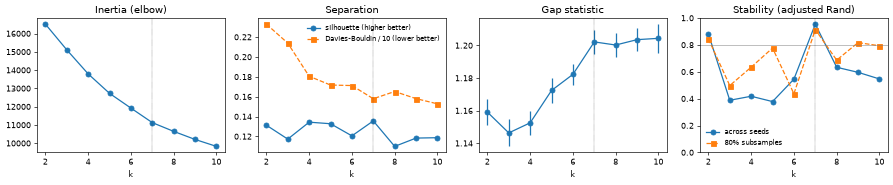

In [5]:
plots.k_metrics(r['metrics'], r['k']);

## Three methods at the chosen k

In [6]:
r['method_scores'].round(3)

,silhouette,davies_bouldin,smallest_group_share
method,,,
kmeans,0.136,1.580,0.029
gmm,0.059,3.243,0.047
ward,0.085,1.883,0.020


In [7]:
r['method_ari'].round(3)

,kmeans,gmm,ward
kmeans,1.000,0.238,0.196
gmm,0.238,1.000,0.155
ward,0.196,0.155,1.000


## Group profiles

- Median yearly growth in each group, % per year
- Names come from the numbers: Growing / Steady / Shrinking from jobs and people after 2019, then the measure that stands out most

In [8]:
r['profile'].round(2)

,jobs_growth_before,jobs_growth_after,pop_growth_before,pop_growth_after,rent_growth_before,rent_growth_after,tracts
trend_group,,,,,,,
Steady: close to the state median,-0.40,-0.76,-0.63,0.31,0.47,-0.02,1001
Steady: people grew fast before 2019,0.65,-0.15,2.04,-0.84,1.49,0.81,490
Steady: rents rose fast after 2019,1.11,0.54,-0.11,0.45,-2.27,4.78,478
Shrinking: jobs grew fast before 2019,6.83,-0.99,0.07,-0.15,0.57,-0.03,433
Steady: rents rose fast before 2019,1.11,0.28,-0.04,0.28,4.34,-3.68,404
Growing: jobs jumped after 2019,-1.35,8.50,-0.27,0.10,0.82,1.02,265
Growing: population jump after 2019,1.93,0.65,0.41,15.72,1.27,0.72,92


Share of each group's tracts whose change is bigger than its ACS margin of error

In [9]:
groups.moe_by_group(r['trends']).round(2)

,share_pop_before_beyond_moe,share_pop_after_beyond_moe,share_rent_before_beyond_moe,share_rent_after_beyond_moe
trend_group,,,,
Growing: jobs jumped after 2019,0.20,0.28,0.14,0.21
Growing: population jump after 2019,0.47,1.00,0.27,0.25
Not enough data,0.27,0.41,0.14,0.15
Shrinking: jobs grew fast before 2019,0.21,0.31,0.14,0.12
Steady: close to the state median,0.25,0.25,0.12,0.11
Steady: people grew fast before 2019,0.48,0.26,0.23,0.18
Steady: rents rose fast after 2019,0.26,0.34,0.18,0.41
Steady: rents rose fast before 2019,0.24,0.32,0.43,0.29


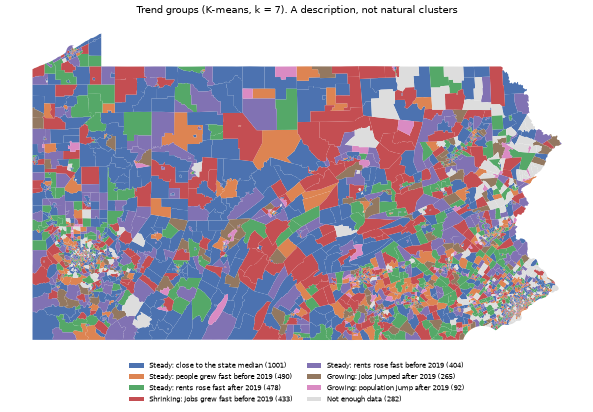

In [10]:
plots.groups_map(r['trends'], r['k']);